# MAI-Image-2.6 · 01 · Text and design

<p align="center">
  <img src="../../.github/images/banners/mai-image-2.6.png" alt="MAI-Image-2.6: one tent, one launch kit" width="900" />
</p>

Image generation with legible text, long brand briefs, coordinated variants, and diagrams, from Microsoft AI on Microsoft Foundry.

| | |
|---|---|
| Released | 2026-08-10 (announced; generally available on Foundry by October 2026) |
| Publisher | Microsoft AI |
| Capability | [Image Generation](../../3-primers/image-generation.md) |
| Model card | [MAI-Image-2.6](https://ai.azure.com/catalog/models/MAI-Image-2.6) |
| Announcement | [Release post](https://microsoft.ai/news/mai-image-2-6-launches-at-no-2-on-arena-ahead-of-google-meta-and-xai/) |
| Docs | [Use MAI image models in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image) |
| Deployment | Global Standard, pay-as-you-go |
| Modes | Generate from text · edit with 1–5 reference images · web grounding · auto aspect ratio |
| Picture size | Each side at least 768 px, up to 2,359,296 pixels in total (1536 × 1536) |
| Prompt | Up to 32,000 tokens, English |
| Rate limit | 6 to 36 requests a minute, by quota tier |
| Pricing | [MAI model pricing](https://aka.ms/MAIModelPricing) |
| Notebooks | **01 · Text and design** (this one) · [02 · Edit and compose](mai-image-2.6-02-edit-and-compose.ipynb) · faster sibling: [MAI-Image-2.6-Flash](../mai-image-2.6-flash/) |
| Env vars | `MICROSOFT_FOUNDRY_ENDPOINT` (or `MAI_IMAGE_ENDPOINT`), `AZURE_MAI_IMAGE_26_DEPLOYMENT`, `AZURE_MAI_IMAGE_26_FLASH_DEPLOYMENT`, `MAI_IMAGE_REQUESTS_PER_MINUTE`, `DEMO_MODE` |

> **Replay or live?** This notebook opens in **replay** mode (`DEMO_MODE=replay`): it shows pictures we already made and makes no Azure calls. Replay pictures are **compressed WebP copies** (up to 1024 px) to keep the repo small; a live run saves full-quality PNGs. Switch to `DEMO_MODE=live` in `.env`, or set `DEMO_MODE = "live"` in the env check cell, once the deployment is ready and you want to make your own pictures. See **Before you start** below.

**First time here?** Run [setup.ipynb](../../setup.ipynb) once to create your Microsoft Foundry project and `.env`.

> *"Can MAI-Image-2.6 make the design work for a product launch, with the words spelled right and the product looking like ours?"*

Contoso Outdoors is launching the **TrailMaster X4** tent. We make the pieces a launch needs from words alone: a poster, brand-guided ads, ads in three languages, a catalog page, material close-ups, and a setup guide. These pictures became the shared [Contoso Outdoors images](../../2-scenarios/contoso-retail/) that the fal video capsules animate.

## What We Will Do

- Put real words on pictures: a full poster, then ads in English, Spanish, and Japanese
- Compare a 5-word brief with a full brand guide, and keep four colorways looking like one product
- Check materials up close, score a detailed brief, and draft a setup diagram

> Run each cell with **Shift + Enter**. Guess first: before each picture, predict one thing it will get right and one it will get wrong.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Before you start

**Just reading?** Leave `DEMO_MODE=replay`. The notebook shows pictures saved in `examples/` (some point at the shared [Contoso Outdoors images](../../2-scenarios/contoso-retail/data/generated/images/)) and makes no Azure calls.

**Running it live?** We need an **MAI-Image-2.6** deployment in our Foundry project, a sign-in with a Foundry role (run `az login`; we use keyless Microsoft Entra ID tokens), and `DEMO_MODE=live` in `.env`. Our pictures go to `output/`, which git ignores, and replay shows them first from then on. Live mode never writes to the scenario folder.

In [1]:
import os
import sys
from pathlib import Path

from dotenv import load_dotenv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "1-scripts" / "mai_image.py").exists())
load_dotenv(ROOT / ".env")

DEMO_MODE = None  # Set to "live" or "replay" to override .env
MODE = (DEMO_MODE or os.getenv("DEMO_MODE") or "replay").strip().lower()
ENDPOINT = (os.getenv("MAI_IMAGE_ENDPOINT") or os.getenv("MICROSOFT_FOUNDRY_ENDPOINT", "")).strip()
HERO = os.getenv("AZURE_MAI_IMAGE_26_DEPLOYMENT", "MAI-Image-2.6").strip()
FLASH = os.getenv("AZURE_MAI_IMAGE_26_FLASH_DEPLOYMENT", "MAI-Image-2.6-Flash").strip()
RPM = int(os.getenv("MAI_IMAGE_REQUESTS_PER_MINUTE", "6"))

if MODE not in ("replay", "live"):
    raise SystemExit(f'DEMO_MODE is "{MODE}". Use "replay" or "live".')

credential = None
if MODE == "live":
    if not ENDPOINT.startswith("https://"):
        raise SystemExit("No endpoint in .env. Set MAI_IMAGE_ENDPOINT (or MICROSOFT_FOUNDRY_ENDPOINT) to the project that has the MAI deployments.")
    from azure.identity import DefaultAzureCredential

    credential = DefaultAzureCredential()
    try:
        credential.get_token("https://cognitiveservices.azure.com/.default")
    except Exception as error:
        raise SystemExit(f"Couldn't get a Microsoft Entra token. Run `az login` in a terminal, then run this cell again.\n{error}")

print(f"Mode: {MODE} | {HERO} and {FLASH} | {RPM} requests per minute per deployment")

Mode: live | MAI-Image-2.6 and MAI-Image-2.6-Flash | 6 requests per minute per deployment


The shared helper in [1-scripts/mai_image.py](../../1-scripts/mai_image.py) sends each request with our Entra ID token, keeps to the rate limit, saves the PNG and a run log (model, seconds, size) to `output/`, and replays saved pictures. `show()` draws small thumbnails, so the notebook stays light, and links each full-size file.

In [2]:
sys.path.insert(0, str(ROOT / "1-scripts"))
from mai_image import MaiImage

HERE = ROOT / "4-models" / "mai-image-2.6"
SCENARIO = ROOT / "2-scenarios" / "contoso-retail" / "data" / "generated" / "images"
mai = MaiImage(ENDPOINT, here=HERE, mode=MODE, requests_per_minute=RPM, credential=credential)
show = mai.show

# The tent, described once, so every picture shows the same tent.
TENT = "TrailMaster X4 Tent"
LOOK = ("a four-person dome tent with a forest-green body, a burnt-orange rainfly, black mesh panels, "
        "grey reflective guylines and a small white 'OutdoorLiving' logo on the front door")

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 1. Can it put real words on a poster?

Text has long been the weak spot of image models: misspelled headlines, melted letters, prices that turn into squiggles. We start with the hardest test: a headline, a product name, a price badge, feature lines, and a footer.

> 🔮 **Guess first:** of the five pieces of text, how many will come out spelled exactly right?

   01-launch-poster: MAI-Image-2.6 | 29.4 s | 1024×1536



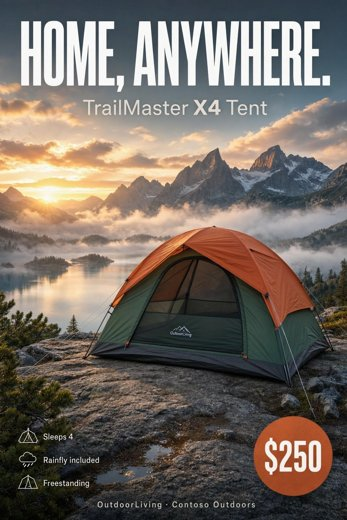

Full size: [Launch poster](../../2-scenarios/contoso-retail/data/generated/images/launch-poster.webp)

In [3]:
POSTER = f"""A magazine-cover style launch poster for the {TENT}.
Photo: {LOOK}, pitched on a granite ledge above a misty alpine lake at sunrise.
Text, exactly as written, from most to least important:
1. Huge bold condensed headline across the top: "HOME, ANYWHERE."
2. Under it, medium weight: "TrailMaster X4 Tent"
3. A round burnt-orange price badge in the lower right: "$250"
4. Three short lines with small line icons, lower left: "Sleeps 4" / "Rainfly included" / "Freestanding"
5. Small footer along the bottom: "OutdoorLiving · Contoso Outdoors"
Clean layout with generous margins. No other text."""

poster = mai.generate(POSTER, "01-launch-poster", HERO, size=(1024, 1536))
show({"Launch poster": poster}, height=520)

**What to look for:** every word spelled as written, including the price and the dot in the footer. The hierarchy: headline, then name, then price. The tent itself: green body, orange rainfly, white logo. Small text is the hardest; if a footer letter wobbles, a second run often fixes it.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 2. Does a longer brief make a better picture?

MAI-Image-2.6 reads prompts up to 32,000 tokens: room for a whole brand guide, not just a sentence. We send three briefs for the same poster: 5 words, about 50, and a page of brand rules.

> 🔮 **Guess first:** will the longest brief look *better*, or just *busier*?

   02-brief-short: MAI-Image-2.6 | 26.5 s | 1024×1280
   02-brief-medium: MAI-Image-2.6 | 27.1 s | 1024×1280
   02-brief-long: MAI-Image-2.6 | 44.6 s | 1024×1280



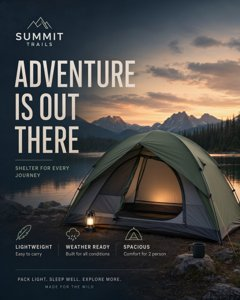
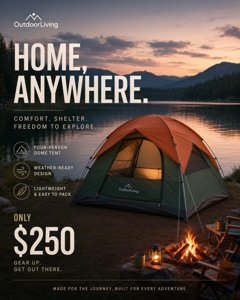
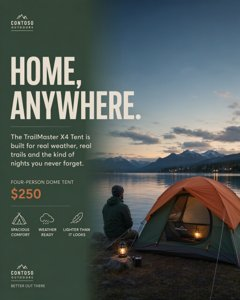

Full size: [short · 5 words](examples/02-brief-short.webp) · [medium · 58 words](examples/02-brief-medium.webp) · [long · 279 words](examples/02-brief-long.webp)

In [4]:
SHORT_BRIEF = "A poster for a tent."

MEDIUM_BRIEF = f"""A poster for the {TENT} by OutdoorLiving: {LOOK}, at a lakeside campsite at dusk.
Headline: "HOME, ANYWHERE." Price: "$250". Warm, friendly and outdoorsy, with lots of space around the text."""

BRAND_GUIDE = """CONTOSO OUTDOORS BRAND GUIDE (summary for designers)
Voice: warm, unhurried and a little playful. We sell the feeling of arriving, not the gear itself.
Colors: Forest Green #2F5D3A for backgrounds and large shapes. Burnt Orange #D9692B only for one accent per layout,
usually the price or a call to action. Bone #F3EDE2 for text panels. Never pure black or pure white.
Type: headlines in a heavy condensed sans-serif, all caps, tight letter spacing. Body text in a friendly rounded
sans-serif. Never more than three type sizes on one layout. Left-align text; never center long lines.
Photography: real places, real weather, natural light. Golden hour or blue hour. People shown from behind or in
profile, looking at the view, never posing at the camera. Gear looks used but cared for: a little dust is fine.
Composition: the product takes up no more than a third of the frame. Leave a calm, empty area for text. Horizon
lines sit on the lower third. One clear focal point per layout.
Logo: the small 'Contoso Outdoors' wordmark sits in the bottom-left corner, in Bone, never on a busy background.
Avoid: lens flare, heavy filters, neon colors, stock-photo smiles, drop shadows on text, more than one exclamation mark."""

LONG_BRIEF = f"""{BRAND_GUIDE}
THE JOB: a launch poster for the {TENT} by OutdoorLiving: {LOOK}.
Scene: blue hour at a quiet lakeside campsite, a lantern glowing inside the tent, one hiker seen from behind on the shore.
Headline: "HOME, ANYWHERE." Price, as the single orange accent: "$250". Follow the brand guide exactly."""

BRIEFS = {"short": SHORT_BRIEF, "medium": MEDIUM_BRIEF, "long": LONG_BRIEF}
briefs = {f"{label} · {len(brief.split())} words": mai.generate(brief, f"02-brief-{label}", HERO, size=(1024, 1280))
          for label, brief in BRIEFS.items()}
show(briefs)

**What to look for:** pick three rules from the brand guide and check them in the third picture: one orange accent only, logo bottom left, hiker seen from behind. Each rule it follows is one less round of feedback. Expect *most* rules, not always all of them: "fewer revision rounds", not "no revisions".

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 3. Can it write in other languages?

The model card says text in pictures is optimized for English, so this is an honest test. The **instructions stay in English** (the model reads English prompts); only the words *on* the ad change language.

> 🔮 **Guess first:** rank English, Spanish, and Japanese from best to worst text.

   03-ad-english: MAI-Image-2.6 | 22.7 s | 1024×1024
   03-ad-spanish: MAI-Image-2.6 | 70.5 s | 1024×1024
   03-ad-japanese: MAI-Image-2.6 | 23.3 s | 1024×1024



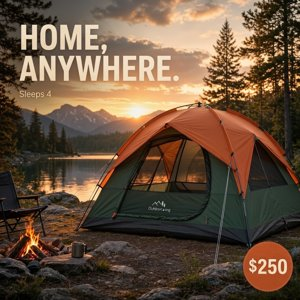
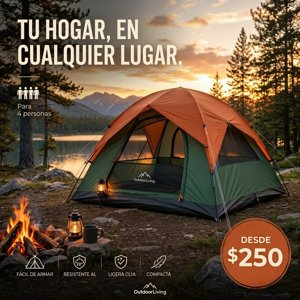
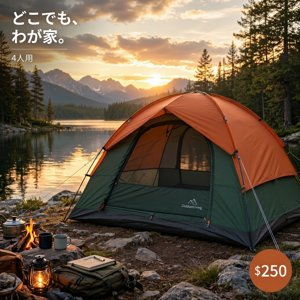

Full size: [English](examples/03-ad-english.webp) · [Spanish](examples/03-ad-spanish.webp) · [Japanese](examples/03-ad-japanese.webp)

In [5]:
HEADLINES = {
    "English": ("HOME, ANYWHERE.", "Sleeps 4"),
    "Spanish": ("TU HOGAR, EN CUALQUIER LUGAR.", "Para 4 personas"),
    "Japanese": ("どこでも、わが家。", "4人用"),
}

ads = {}
for language, (headline, sleeps) in HEADLINES.items():
    prompt = f"""A clean outdoor ad for the {TENT}: {LOOK}, at a forest campsite at golden hour.
Write this text exactly, in {language}, keeping every character and accent:
Headline at the top: "{headline}"
Small line under the product: "{sleeps}"
Price badge: "$250"
The same layout every time: headline top left, badge bottom right."""
    ads[language] = mai.generate(prompt, f"03-ad-{language.lower()}", HERO, size=(1024, 1024))
show(ads)

**What to look for:** accents in Spanish and every Japanese character; a native speaker is the best judge. Expect English to be strongest. For other languages, review every word, or add the text afterwards in a design tool.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 4. Do four colorways still look like one product?

Catalog pages need coordinated variants: the same product, angle, and labels, with only the color and setting changing. We ask for all four panels in one picture.

> 🔮 **Guess first:** what drifts first between panels: the shape, the logo, or the labels?

   04-four-seasons: MAI-Image-2.6 | 35.4 s | 1536×1536



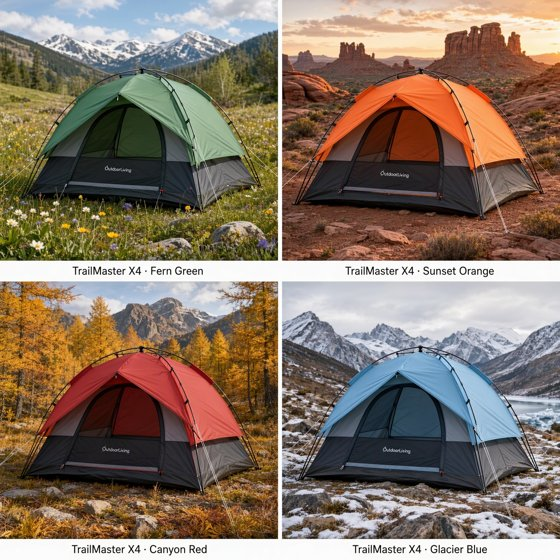

Full size: [Four colorways, one tent](../../2-scenarios/contoso-retail/data/generated/images/four-seasons.webp)

In [6]:
CATALOG = f"""A 2x2 product catalog page, four equal panels separated by thin white gutters.
Every panel shows the same tent model from the same three-quarter front angle: {LOOK.replace("a burnt-orange rainfly", "a rainfly")}.
Keep the tent's shape, pole layout, door, logo position and guylines identical in all four panels.
Only the rainfly color and the setting change:
- Top left: fern-green rainfly, spring meadow with wildflowers. Label: "TrailMaster X4 · Fern Green"
- Top right: sunset-orange rainfly, red desert slickrock. Label: "TrailMaster X4 · Sunset Orange"
- Bottom left: canyon-red rainfly, golden autumn larch forest. Label: "TrailMaster X4 · Canyon Red"
- Bottom right: glacier-blue rainfly, a late-season dusting of snow. Label: "TrailMaster X4 · Glacier Blue"
Each label sits in a white strip along the bottom of its panel, in the same font, size and position."""

catalog = mai.generate(CATALOG, "04-four-seasons", HERO, size=(1536, 1536))
show({"Four colorways, one tent": catalog}, height=560)

**What to look for:** the same shape and pole layout in all four panels, the logo in the same spot, and four matching labels. Small details like the logo drift first. For hundreds of variants, make one approved picture and **edit** it per color, as in [notebook 02](mai-image-2.6-02-edit-and-compose.ipynb): edits keep more of the original.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 5. Do materials hold up close?

Materials are where pictures give themselves away. Four extreme close-ups, each testing one thing: **texture**, **reflection**, **transparency**, and **deformation** (how things squash and bend).

   05-touch-texture: MAI-Image-2.6 | 22.6 s | 1024×1024
   05-touch-reflection: MAI-Image-2.6 | 22.7 s | 1024×1024
   05-touch-transparency: MAI-Image-2.6 | 24.6 s | 1024×1024
   05-touch-deformation: MAI-Image-2.6 | 23.9 s | 1024×1024



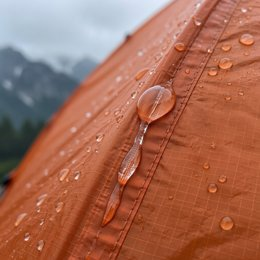
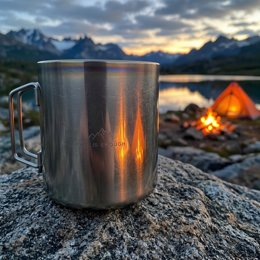
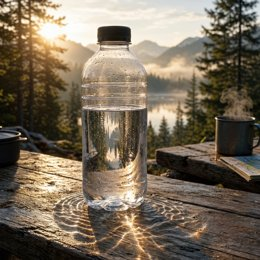
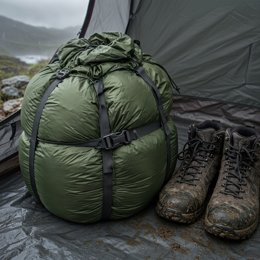

Full size: [Texture](examples/05-touch-texture.webp) · [Reflection](examples/05-touch-reflection.webp) · [Transparency](examples/05-touch-transparency.webp) · [Deformation](examples/05-touch-deformation.webp)

In [7]:
MATERIALS = {
    "texture": "Extreme macro photo of rain on a burnt-orange ripstop polyester tent rainfly: round water beads sitting on the visible fabric weave, two beads merging and running down a taped seam, overcast light, shallow depth of field.",
    "reflection": "Close-up of a brushed titanium camping mug on a granite rock at dusk: faint blue-gold heat tint near the rim, fine scratches, and an orange tent and a small campfire reflected and stretched across the mug's curved side.",
    "transparency": "A clear water bottle, half full, standing on a weathered wooden camp table in low morning sun: light bending through the water and casting a bright rippled pattern on the wood, the forest behind seen upside down through the bottle, condensation drops on the outside.",
    "deformation": "A green nylon stuff sack crammed with a sleeping bag, compression straps pulled tight so the fabric bulges and wrinkles between them, one plastic buckle visibly under strain, lying on a tent floor next to muddy boots.",
}
close_ups = {kind.title(): mai.generate(prompt, f"05-touch-{kind}", HERO) for kind, prompt in MATERIALS.items()}
show(close_ups, height=260)

**What to look for:** the physics. Do the beads sit *on* the weave? Is the reflection bent by the mug's curve? Is the forest flipped inside the bottle? Do wrinkles bunch *between* the straps? Look at edges where two materials meet: that's where small mistakes hide.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 6. How many details of a specific brief does it get right?

Seven exact details: a time on a watch, things to the *left* and *under*, one mug upright and one tipped over, and an exact count. Then we score it. A scorecard turns "looks good" into a number we can compare, which is the start of an evaluation.

> 🔮 **Guess first:** out of 7, what will it score?

   06-clockwork: MAI-Image-2.6 | 28.7 s | 1536×1024



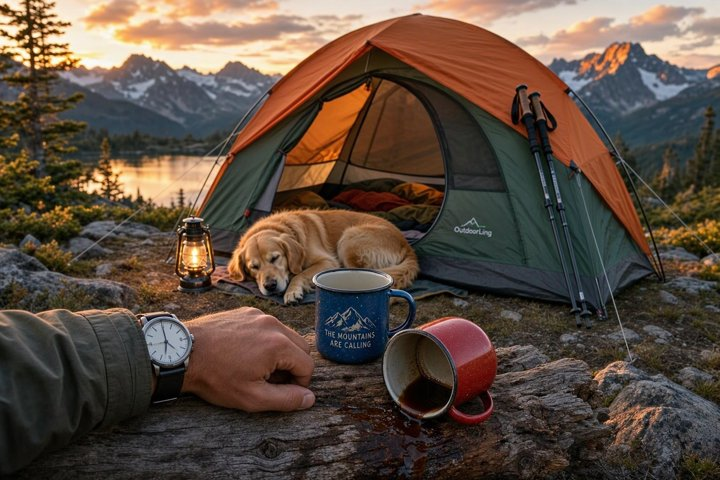

Full size: [Seven details](examples/06-clockwork.webp)

In [8]:
CLOCKWORK = f"""Photo of a campsite at golden hour.
Foreground: a hiker's left wrist resting on a log, wearing an analog watch with a white face. The hands clearly show 6:45.
Behind: the {TENT}, {LOOK}, with its front door rolled open.
A lit lantern stands on the ground to the LEFT of the open door.
A golden retriever sleeps curled up under the tent's vestibule.
On the log next to the wrist: a blue enamel mug standing upright, and a red enamel mug tipped over on its side with coffee spilling onto the wood.
Exactly three trekking poles lean against the right side of the tent."""

clockwork = mai.generate(CLOCKWORK, "06-clockwork", HERO, size=(1536, 1024))
show({"Seven details": clockwork}, height=480)

Now we judge. Change each `None` to `True` (it's there) or `False` (it isn't), then run the cell.

In [ ]:
scorecard = {
    "The watch shows 6:45": None,
    "The tent door is open": None,
    "The lantern is LEFT of the door": None,
    "A dog is asleep under the vestibule": None,
    "The blue mug is upright": None,
    "The red mug is tipped over, spilling": None,
    "Exactly three trekking poles, on the right": None,
}

scored = {check: result for check, result in scorecard.items() if result is not None}
if not scored:
    print("Fill in the scorecard first: True or False for each line.")
else:
    for check, result in scored.items():
        print(f"{'yes' if result else 'no ':3}  {check}")
    print(f"\nScore: {sum(scored.values())} out of {len(scored)}")

no   The watch shows 6:45
yes  The tent door is open
yes  The lantern is LEFT of the door
yes  A dog is asleep under the vestibule
yes  The blue mug is upright
yes  The red mug is tipped over, spilling
yes  Exactly three trekking poles, on the right

Score: 6 out of 7


**What to look for:** which *kind* of detail it got right. Models often nail *what's there* but slip on *where* (left vs right) and *how many*; clock times are a classic trap. One run is one sample: run it three times and average before quoting a number.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 7. Can it draft a diagram?

A diagram has to get names, connections, and order right at once. We ask for a three-step setup guide with labeled parts.

   07-setup-guide: MAI-Image-2.6 | 29.6 s | 1536×1024



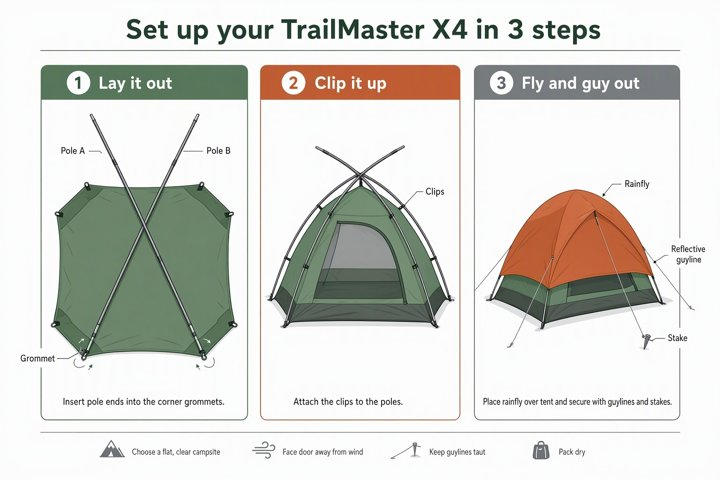

Full size: [Setup guide](../../2-scenarios/contoso-retail/data/generated/images/setup-guide.webp)

In [10]:
SETUP_GUIDE = f"""A clean instructional infographic in a flat vector style on a white background.
Title across the top: "Set up your TrailMaster X4 in 3 steps".
Three numbered panels, left to right, in green, orange and grey only:
1 "Lay it out": the green tent body flat on the ground, two grey poles labeled "Pole A" and "Pole B" crossing in an X, with arrows showing each pole end going into a corner ring labeled "Grommet".
2 "Clip it up": the tent body standing, with small clips labeled "Clips" attaching the body to the poles.
3 "Fly and guy out": the burnt-orange rainfly labeled "Rainfly" over the top, grey cords labeled "Reflective guyline" running down to pegs labeled "Stake".
Thin leader lines connect every label to the exact part it names."""

guide = mai.generate(SETUP_GUIDE, "07-setup-guide", HERO, size=(1536, 1024))
show({"Setup guide": guide}, height=480)

**What to look for:** the title spelled right, steps numbered 1, 2, 3, and every label pointing at the right part. Treat diagrams as a strong first draft: someone who knows the product checks every label before it ships.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

### 🔧 Break it on purpose

Each side of a picture must be at least 768 pixels. What happens if we ask for a 700-pixel-wide sticker?

In [11]:
if MODE == "live":
    try:
        mai.generate("A round sticker that says 'HOME, ANYWHERE.'", "break-too-narrow", HERO, size=(700, 1024))
    except RuntimeError as error:
        print(error)
else:
    print("Replay mode: in live mode the service answers 400 and says which size rule we broke. Nothing is drawn or billed.")

400 from MAI-Image-2.6. The model didn't accept a setting. Check the size (each side 768 or more, 2,359,296 pixels at most), the image type (PNG or JPEG), and the options.
Model does not support request parameter value supplied: 'width' must be at least 768 pixels.


The model says no instead of quietly resizing, so a wrong-sized picture never ships unnoticed. The message names the rule; the fix is a size of 768 or more on each side.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Your Turn to Explore

- **Longer headline.** Change the poster headline to "Your new favorite room has no walls". Does the layout still hold?
- **A stricter brand rule.** Add "Every headline ends with a period" to `BRAND_GUIDE`. Does the long brief follow it?
- **Right to left.** Add `"Arabic": ("بيتك في أي مكان", "يتسع لأربعة")` to `HEADLINES`. Does the layout flip?

In [12]:
# Your experiment here. Try: mai.generate("...", "my-picture", HERO, size=(1024, 1024))

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## What We Did

- ✅ Put real words on pictures: a full poster, then ads in English, Spanish, and Japanese
- ✅ Compared a 5-word brief with a full brand guide, and kept four colorways looking like one product
- ✅ Checked materials up close, scored a detailed brief, and drafted a setup diagram

➡️ **Next:** [02 · Edit and compose](mai-image-2.6-02-edit-and-compose.ipynb): fix photos we already have, and put five products into one scene.

Stuck? [Open an issue](https://github.com/microsoft-foundry/model-releases/issues/new) with the failing cell's output.

**Learn more:** [Use MAI image models in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image) · [Image Generation primer](../../3-primers/image-generation.md) · [Release post](https://microsoft.ai/news/mai-image-2-6-launches-at-no-2-on-arena-ahead-of-google-meta-and-xai/)